# A — Auto-encodeurs couleur
**Amjad AAYD et [information masquée] — [information masquée]**

Adaptation du TP AE / VAE / CVAE / PixelCNN à **CIFAR-10**, selon la demande orale
rapportée par l'étudiant. « CIFAR dix » est l'interprétation retenue du nom entendu.
Le PDF d'origine utilise FashionMNIST et MNIST ; cette version utilise CIFAR-10
pour les quatre blocs. Les images restent en couleur, sans conversion en gris.

Lire de haut en bas : **objectif → code commenté → sortie → explication**.
Les classes Python ne sont utilisées que pour définir les réseaux PyTorch.
Les boucles d'apprentissage restent visibles et explicites.

In [1]:
# Importer uniquement les bibliothèques utilisées dans ce notebook.
from pathlib import Path
import json
import time
import random
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import CIFAR10
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Fixer les tirages pour pouvoir refaire une expérience comparable.
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(6)

# Utiliser le GPU si ce PC en possède un ; sinon utiliser le processeur.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Calcul sur :", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

# Tous les fichiers créés restent dans le dossier de ce TP.
racine = Path.cwd()
(racine / "figures").mkdir(exist_ok=True)
(racine / "models").mkdir(exist_ok=True)
debut = time.time()

Calcul sur : cuda
NVIDIA GeForce RTX 5070 Ti Laptop GPU


## Charger les images couleur
Une image contient **3 × 32 × 32 = 3 072 nombres** : rouge, vert et bleu.
La division par 255 place les intensités dans [0,1]. Le test est chargé séparément
et ne sert jamais à ajuster les poids. Les classes ne supervisent que le CVAE.

In [2]:
# Télécharger les vraies images CIFAR-10 avec torchvision.
# Au prochain lancement, les fichiers locaux sont réutilisés.
train = CIFAR10(root="data", train=True, download=True)
test = CIFAR10(root="data", train=False, download=True)

# CIFAR stocke [image, hauteur, largeur, couleur].
# PyTorch attend [image, couleur, hauteur, largeur].
x_train = torch.tensor(train.data).permute(0, 3, 1, 2).float() / 255.0
x_test = torch.tensor(test.data).permute(0, 3, 1, 2).float() / 255.0
y_train = torch.tensor(train.targets)
y_test = torch.tensor(test.targets)

# Former des lots de 128 images pour l'apprentissage.
donnees_train = TensorDataset(x_train, y_train)
chargeur = DataLoader(donnees_train, batch_size=128, shuffle=True)
classes = ["avion", "voiture", "oiseau", "chat", "cerf",
           "chien", "grenouille", "cheval", "bateau", "camion"]
print("Apprentissage :", x_train.shape)
print("Test :", x_test.shape)
print("Classes :", classes)
assert x_train.shape == (50000, 3, 32, 32)
assert x_test.shape == (10000, 3, 32, 32)

Apprentissage : torch.Size([50000, 3, 32, 32])
Test : torch.Size([10000, 3, 32, 32])
Classes : ['avion', 'voiture', 'oiseau', 'chat', 'cerf', 'chien', 'grenouille', 'cheval', 'bateau', 'camion']


In [3]:
# Cette fonction sert seulement à afficher et sauvegarder une grille de couleurs.
# permute remet les couleurs en dernier, comme attendu par matplotlib.
def afficher(images, titre, fichier, colonnes=8):
    images = images.detach().cpu().clamp(0, 1)
    lignes = (len(images) + colonnes - 1) // colonnes
    figure, axes = plt.subplots(lignes, colonnes,
                               figsize=(colonnes * 1.4, lignes * 1.5),
                               squeeze=False)
    for numero, axe in enumerate(axes.flat):
        axe.axis("off")
        if numero < len(images):
            axe.imshow(images[numero].permute(1, 2, 0))
    figure.suptitle(titre)
    figure.tight_layout()
    chemin = racine / "figures" / fichier
    figure.savefig(chemin, dpi=140, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(chemin)))

# Une seconde petite fonction affiche une courbe déjà calculée.
def courbe(valeurs, titre, fichier):
    plt.figure(figsize=(6, 3))
    plt.plot(range(1, len(valeurs) + 1), valeurs, marker="o")
    plt.xlabel("Époque")
    plt.ylabel("Perte moyenne")
    plt.title(titre)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    chemin = racine / "figures" / fichier
    plt.savefig(chemin, dpi=140)
    plt.close()
    display(Image(filename=str(chemin)))

## A1 — AE dense
On adapte uniquement le nombre de pixels : 784 devient 3 072. Le code latent
reste de dimension 128. La sigmoïde finale correspond aux intensités dans [0,1].

In [4]:
# Définir un AE dense : chaque image est un vecteur de 3 072 nombres.
class AEDense(nn.Module):
    def __init__(self):
        super().__init__()
        self.encodeur = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 128)
        )
        self.decodeur = nn.Sequential(
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            nn.Linear(1024, 3072), nn.Sigmoid(),
            nn.Unflatten(1, (3, 32, 32))
        )

    # Compresser l'image, puis reconstruire les trois couleurs.
    def forward(self, x):
        z = self.encodeur(x)
        reconstruction = self.decodeur(z)
        return reconstruction

In [5]:
# Cette boucle est commune aux trois AEs : seule l'amplitude du bruit change.
# bruit=0 : AE classique. bruit=0.3 : DAE, avec une cible toujours propre.
def entrainer_ae(modele, nom, bruit=0.0):
    modele = modele.to(device)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=0.001)
    pertes = []
    for epoque in range(10):
        modele.train()
        somme = 0.0
        for images, etiquettes in chargeur:
            images = images.to(device)
            # Ajouter éventuellement du bruit, puis limiter les valeurs à [0,1].
            entrees = (images + bruit * torch.randn_like(images)).clamp(0, 1)
            # Vider les anciens gradients avant le nouveau calcul.
            optimiseur.zero_grad()
            sorties = modele(entrees)
            # Comparer la sortie à l'image propre, même pour le DAE.
            erreur = F.mse_loss(sorties, images)
            erreur.backward()
            optimiseur.step()
            somme += erreur.item() * len(images)
        moyenne = somme / len(x_train)
        pertes.append(moyenne)
        print(nom, "époque", epoque + 1, "MSE", moyenne, flush=True)
    modele.eval()
    torch.save(modele.state_dict(), racine / "models" / (nom + ".pt"))
    return modele, pertes

AE_dense époque 1 MSE 0.031562384638786314


AE_dense époque 2 MSE 0.02249757889688015


AE_dense époque 3 MSE 0.019596799866557123


AE_dense époque 4 MSE 0.01696845822632313


AE_dense époque 5 MSE 0.016047987600564955


AE_dense époque 6 MSE 0.015346653424501418


AE_dense époque 7 MSE 0.014675576067268848


AE_dense époque 8 MSE 0.013839120526313782


AE_dense époque 9 MSE 0.013254017580747604


AE_dense époque 10 MSE 0.012840358445346355


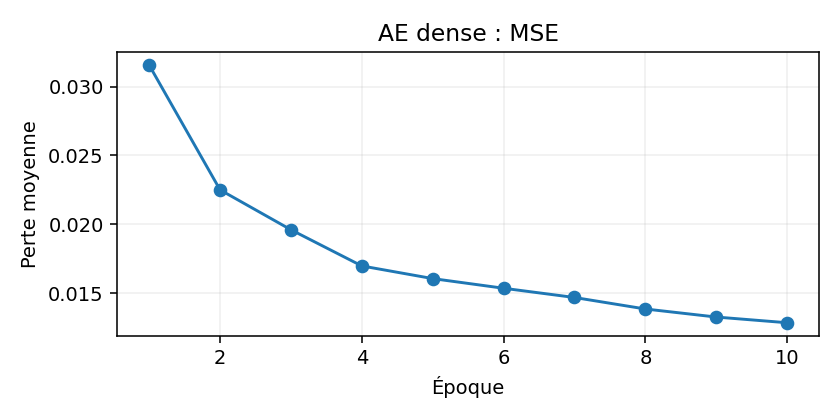

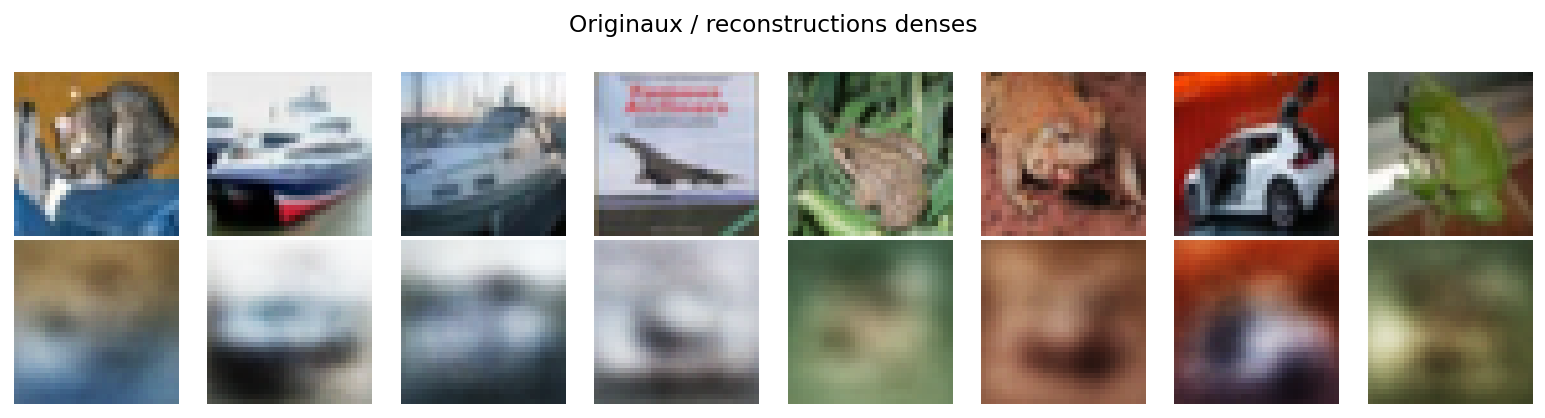

In [6]:
# Entraîner le dense sur les 50 000 images, puis regarder sa courbe.
dense, pertes_dense = entrainer_ae(AEDense(), "AE_dense")
courbe(pertes_dense, "AE dense : MSE", "A_dense_perte.png")
with torch.no_grad():
    recon_dense = dense(x_test[:8].to(device)).cpu()
afficher(torch.cat([x_test[:8], recon_dense]),
         "Originaux / reconstructions denses", "A_dense_images.png")

## A2 — AE convolutionnel
Les filtres travaillent sur les voisinages de pixels, avec 3 canaux d'entrée.
On utilise les mêmes images test pour comparer les reconstructions.

In [7]:
# Deux convolutions réduisent les dimensions : 32 → 16 → 8.
class AEConv(nn.Module):
    def __init__(self):
        super().__init__()
        self.encodeur = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128)
        )
        # Les convolutions transposées reconstruisent : 8 → 16 → 32.
        self.decodeur = nn.Sequential(
            nn.Linear(128, 64 * 8 * 8), nn.ReLU(),
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encodeur(x)
        reconstruction = self.decodeur(z)
        return reconstruction

In [ ]:
# Répéter la même procédure avec le modèle convolutionnel.
conv, pertes_conv = entrainer_ae(AEConv(), "AE_conv")
courbe(pertes_conv, "AE convolutionnel : MSE", "A_conv_perte.png")
with torch.no_grad():
    recon_conv = conv(x_test[:8].to(device)).cpu()
afficher(torch.cat([x_test[:8], recon_dense, recon_conv]),
         "Originaux / dense / convolutionnel", "A_comparaison.png")

## A3 — Débruitage
On entraîne un troisième modèle avec des entrées bruitées et des cibles propres.
Puis on compare l'AE classique et le DAE pour plusieurs amplitudes de bruit.

In [ ]:
# Le bruit d'apprentissage a un écart-type de 0,3.
dae, pertes_dae = entrainer_ae(AEConv(), "DAE", bruit=0.3)
courbe(pertes_dae, "DAE : MSE", "A_dae_perte.png")
torch.manual_seed(123)
images_bruitees = (x_test[:8] + 0.3 * torch.randn_like(x_test[:8])).clamp(0, 1)
with torch.no_grad():
    sorties_conv = conv(images_bruitees.to(device)).cpu()
    sorties_dae = dae(images_bruitees.to(device)).cpu()
afficher(torch.cat([x_test[:8], images_bruitees, sorties_conv, sorties_dae]),
         "Propres / bruitées / AE propre / DAE", "A_debruitage.png")

In [ ]:
# Mesurer la MSE sur les 10 000 images test, avec le même bruit pour les deux modèles.
mesures = []
for sigma in [0.0, 0.1, 0.3, 0.5]:
    total_conv = 0.0
    total_dae = 0.0
    generateur = torch.Generator().manual_seed(123)
    with torch.no_grad():
        for propres in x_test.split(128):
            bruit = torch.randn(propres.shape, generator=generateur) * sigma
            entrees = (propres + bruit).clamp(0, 1).to(device)
            total_conv += F.mse_loss(conv(entrees).cpu(), propres, reduction="sum").item()
            total_dae += F.mse_loss(dae(entrees).cpu(), propres, reduction="sum").item()
    ligne = {"sigma": sigma, "AE_conv_MSE": total_conv / x_test.numel(),
             "DAE_MSE": total_dae / x_test.numel()}
    mesures.append(ligne)
    print(ligne)

# Calculer aussi l'erreur du dense sur le test propre.
total_dense = 0.0
with torch.no_grad():
    for images in x_test.split(128):
        total_dense += F.mse_loss(dense(images.to(device)).cpu(), images, reduction="sum").item()
mse_dense = total_dense / x_test.numel()
print("MSE test dense :", mse_dense)

## Interpolation : mélanger les codes, pas les pixels
Nous prenons deux images test, calculons leurs codes puis parcourons le segment
entre ces codes. Un AE classique ne garantit pas que chaque mélange soit plausible.

In [ ]:
# alpha=0 donne le premier code ; alpha=1 donne le second.
with torch.no_grad():
    codes = dense.encodeur(x_test[:2].to(device))
    images_interpolees = []
    for alpha in torch.linspace(0, 1, 8):
        z = (1 - alpha) * codes[0] + alpha * codes[1]
        image = dense.decodeur(z.unsqueeze(0))
        images_interpolees.append(image.cpu())
afficher(torch.cat(images_interpolees), "Interpolation AE", "A_interpolation.png")

## t-SNE : regarder les codes en deux dimensions
La projection utilise 1 000 images test, pour limiter le calcul. Les couleurs du
nuage représentent les classes réelles, sans avoir supervisé l'apprentissage AE.
Les distances sont déformées : ce graphique n'est pas un score de qualité.

In [ ]:
# Réduire les 128 coordonnées latentes à deux coordonnées d'affichage.
from sklearn.manifold import TSNE
with torch.no_grad():
    codes = dense.encodeur(x_test[:1000].to(device)).cpu().numpy()
projection = TSNE(n_components=2, random_state=42, perplexity=30,
                  init="pca", learning_rate="auto").fit_transform(codes)
plt.figure(figsize=(6, 4))
points = plt.scatter(projection[:, 0], projection[:, 1], c=y_test[:1000],
                     cmap="tab10", s=8)
plt.colorbar(points, ticks=range(10))
plt.title("AE dense : codes test projetés")
plt.tight_layout()
chemin = racine / "figures" / "A_tsne.png"
plt.savefig(chemin, dpi=140)
plt.close()
display(Image(filename=str(chemin)))

## Réponses aux trois questions A
1. La compression peut rejeter certaines perturbations et conserver les structures
fréquentes ; le débruitage n'est pas garanti sans apprentissage adapté.
2. Les convolutions exploitent les voisinages et partagent leurs filtres entre
positions. Elles conviennent aux images, sans garantir de gagner dans tout protocole.
3. L'AE n'impose pas de distribution latente : l'interpolation peut traverser des
zones qui n'ont jamais été apprises.

In [ ]:
# Sauvegarder uniquement les mesures et courbes calculées pendant cette exécution.
resultats = {"dense_test_MSE": mse_dense, "bruit": mesures,
             "pertes_dense": pertes_dense, "pertes_conv": pertes_conv,
             "pertes_dae": pertes_dae, "secondes": time.time() - debut}
(racine / "resultats_A.json").write_text(json.dumps(resultats, indent=2), encoding="utf-8")
print("Bloc A terminé : 3 modèles entraînés.")